# Discrete and smeared stringers: cylinders with riveted Z stringers (Peterson and Dow 1959; Card and Jones 1966)

Peterson and Dow [1] tested in axial compression 7075-T6 cylinders stiffened
by Z-section stringers riveted inside the skin, 1.25 in apart; Card and Jones
[2] tested the same cylinders with the stringers outside and list both series
in their Table I (p. 7): cylinders 5, 7, 9, 11 (external) and 6, 8, 10, 12
(internal, from [1]), with the test loads and the loads of their
smeared-stiffener theory for clamped ($\bar{N}_c$) and simply supported
($\bar{N}_s$) ends. This notebook builds the cylinders as `MultiDomain`
assemblies with discrete stringers and compares with these values, to
quantify the gap between discrete and smeared stringers at a spacing of 1.25
in (the integral blade cylinders 1 to 4 of [2], 1.0 in apart, are in
`card1966_blade_cylinder_buckling.ipynb`).

A stringer is first represented by one plate strip normal to the skin (a
blade), which cannot reproduce a Z section exactly; two equivalent blades
are used, and the discrete model and the smeared theory are both evaluated
for each, so that the discreteness gap (discrete against smeared, same
blade) is separated from the effect of replacing the Z by a blade. Then the
Z is modelled by three plates (attached flange, web, free flange), with the
dimensions of [1], and cylinders 1 and 2 of [1] ($R = 23.74$ in), not
computed in [2], are compared with their tests.

[1] J. P. Peterson and M. B. Dow, *Compression tests on circular cylinders
stiffened longitudinally by closely spaced Z-section stringers*, NASA Memo
2-12-59L, March 1959.

[2] M. F. Card and R. M. Jones, *Experimental and theoretical results for
buckling of eccentrically stiffened cylinders*, NASA TN D-3639, October 1966,
https://ntrs.nasa.gov/citations/19660027866.

[3] D. L. Block, M. F. Card and M. M. Mikulas, Jr., *Buckling of eccentrically
stiffened orthotropic cylinders*, NASA TN D-2960, 1965,
https://ntrs.nasa.gov/citations/19650021133.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import blade_cylinder_utils as bu
import stringer_cylinder_utils as su


def pct(value, ref):
    return 100*(value/ref - 1)


def table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(out)))

def plot_mode(ax, md_, c, skin, R, title, ns, frac=1.):
    x, th, w = bu.skin_w(md_, c, skin, R)
    sel = th <= frac*th.max() + 1e-12
    ax.pcolormesh(np.degrees(th[sel]), x, (w[sel]/np.abs(w).max()).T, cmap='RdBu_r',
                  shading='auto', vmin=-1, vmax=1)
    pos = (np.arange(ns) + 0.5)*2*np.pi/ns
    pos = pos[pos <= th[sel].max()]
    ax.plot(np.degrees(pos), np.zeros_like(pos), 'k.', ms=3)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(r'$\theta$, deg')

from scipy.optimize import brentq

## Cylinders and the Z section

Table I(a) of [2] (p. 7), $R = 15.92$ in, $E = 10.5 \times 10^3$ ksi, $\mu =
0.32$, 80 stringers 1.25 in apart (Fig. 2(a)); ends ground flat between the
platens (clamped). $\bar{N}$ in lb/in ($\bar{P}_e/(2\pi R)$; the columns are
headed kips/in.). Cylinders 6, 8, 10, 12 of [2] are specimens 6, 5, 3, 4 of
[1], where $R = 15.80$ in and $E = 10\,900$ ksi are printed; the values of
[2] are used.

The Z (Fig. 2(a) of [2], Fig. 2(b) of [1]): sheet 0.040 in, bend radius
0.04 in, depth 0.54 in from the skin surface, attached flange 0.375 in and
free flange 0.22 in overall, nominal dimensions. Its section is computed on
the centre line of the sheet with the two bends (the reading that reproduces
$\bar{N}_c$ and $\bar{N}_s$ of [2] best; the reading with square corners is
compared in the bfsccylinder implementation of this case), $J = \sum b
t^3/3$. Equivalent blades on the skin: **A-z** (same area and centroid) and
**A-Io** (same area and moment of inertia about the middle surface of the
skin). In the model the blade is the plate strip from the middle surface of
the skin to the tip, $H_s = h_b + t/2$, with $D_{66}$ scaled to $G J$ of the
Z; the smeared reference of the gap is equation (15) of [3] for the strip as
modelled ($A = t_b H_s$, $\bar{z} = \pm H_s/2$, $I_o = t_b H_s^3/3$).

In [2]:
E_PSI, MU, R, NS = 10.5e6, 0.32, 15.92, 80
LBF, IN = bu.LBF, bu.IN
E = E_PSI*bu.PSI
d = 2*np.pi*R/NS
CYL = {5: ('external', .0410, 59.00, 1696, 2289, 1193), 6: ('internal', .0401, 59.00, 995, 1174, 766),
       7: ('external', .0391, 41.83, 1863, 2617, 1283), 8: ('internal', .0401, 41.83, 1260, 1383, 773),
       9: ('external', .0392, 29.68, 2730, 3426, 1574), 10: ('internal', .0403, 29.68, 1710, 1813, 838),
       11: ('external', .0395, 20.77, 3780, 4947, 2068), 12: ('internal', .0401, 20.77, 2730, 2845, 1027)}
TZ, RB, HZ, BB, BT = 0.040, 0.04, 0.54, 0.375, 0.22


def z_section(t, side):
    # centre line of the Z with the two bends, z from the skin surface (in)
    rc = RB + TZ/2
    zb, zt = TZ/2, HZ - TZ/2
    a = np.linspace(0, np.pi/2, 41)[:-1] + np.pi/160
    lw = zt - zb - 2*rc
    ds = np.concatenate([[BB - TZ/2 - rc], np.full(40, rc*np.pi/80), np.full(40, lw/40),
                         np.full(40, rc*np.pi/80), [BT - TZ/2 - rc]])
    z = np.concatenate([[zb], zb + rc - rc*np.cos(a), zb + rc + (np.arange(40) + 0.5)*lw/40,
                        zt - rc + rc*np.sin(a), [zt]])
    A = TZ*ds.sum()
    zc = (TZ*ds*z).sum()/A
    Ic = (TZ*ds*(z - zc)**2).sum() + TZ**3/12*(BB + BT)
    sign = 1. if side == 'external' else -1.
    zs = sign*(t/2 + zc)
    return dict(A=A, zc=zc, Io=Ic + A*zs**2, J=ds.sum()*TZ**3/3)


def strips(t, side):
    zz = z_section(t, side)
    sign = 1. if side == 'external' else -1.
    out = {}
    hbs = {'A-z': 2*zz['zc'],
           'A-Io': brentq(lambda hb: zz['A']*hb**2/12 + zz['A']*((t + hb)/2)**2 - zz['Io'], 0.05, 2.)}
    for k, hb in hbs.items():
        tb = zz['A']/hb
        Hs = hb + t/2
        out[k] = dict(tb=tb, hb=hb, Hs=Hs, J=zz['J'], Jplate=Hs*tb**3/3,
                      sec=(tb*Hs, sign*Hs/2, tb*Hs**3/3, zz['J']))
    return zz, out


rows = []
Z, STRIPS = {}, {}
for c, (side, t, L, Ne, Nc, Ns) in CYL.items():
    Z[c], STRIPS[c] = strips(t, side)
    zz = Z[c]
    Nz = su.smeared_ss(R, L, t, E_PSI, MU, d, zz['A'], (1 if side == 'external' else -1)*(t/2 + zz['zc']),
                       zz['Io'], zz['J'], nmax=40)
    row = [c, side, Ne, Nc, Ns, '%.0f %s, %+.1f %%' % (Nz[0], Nz[1], pct(Nz[0], Ns))]
    for k, s in STRIPS[c].items():
        s['smSS'] = su.smeared_ss(R, L, t, E_PSI, MU, d, *s['sec'], nmax=40)
        row.append('%.4f x %.4f; %.0f, %+.1f %%' % (s['tb'], s['hb'], s['smSS'][0], pct(s['smSS'][0], Nz[0])))
    rows.append(row)
print('Z: A = %.5f in^2, centroid %.4f in above the skin, J = %.3e in^4'
      % (Z[5]['A'], Z[5]['zc'], Z[5]['J']))
table(['cyl.', 'stringers', 'test N_e', 'N_c', 'N_s', 'Eq. (15), Z, vs N_s',
       'blade A-z: t_b x h_b, in; Eq. (15) vs Z', 'blade A-Io: t_b x h_b, in; Eq. (15) vs Z'], rows)

Z: A = 0.04014 in^2, centroid 0.2314 in above the skin, J = 2.141e-05 in^4


| cyl. | stringers | test N_e | N_c | N_s | Eq. (15), Z, vs N_s | blade A-z: t_b x h_b, in; Eq. (15) vs Z | blade A-Io: t_b x h_b, in; Eq. (15) vs Z |
|---|---|---|---|---|---|---|---|
| 5 | external | 1696 | 2289 | 1193 | 1193 (1, 6), -0.0 % | 0.0867 x 0.4628; 1178, -1.2 % | 0.0763 x 0.5263; 1223, +2.5 % |
| 6 | internal | 995 | 1174 | 766 | 765 (1, 6), -0.2 % | 0.0867 x 0.4628; 750, -1.9 % | 0.0763 x 0.5263; 745, -2.5 % |
| 7 | external | 1863 | 2617 | 1283 | 1281 (1, 7), -0.1 % | 0.0867 x 0.4628; 1245, -2.8 % | 0.0762 x 0.5264; 1320, +3.0 % |
| 8 | internal | 1260 | 1383 | 773 | 772 (1, 7), -0.1 % | 0.0867 x 0.4628; 737, -4.6 % | 0.0763 x 0.5263; 742, -3.9 % |
| 9 | external | 2730 | 3426 | 1574 | 1572 (1, 9), -0.1 % | 0.0867 x 0.4628; 1492, -5.1 % | 0.0763 x 0.5264; 1612, +2.5 % |
| 10 | internal | 1710 | 1813 | 838 | 836 (1, 8), -0.2 % | 0.0867 x 0.4628; 760, -9.1 % | 0.0763 x 0.5263; 788, -5.7 % |
| 11 | external | 3780 | 4947 | 2068 | 2066 (1, 10), -0.1 % | 0.0867 x 0.4628; 1898, -8.1 % | 0.0763 x 0.5264; 2117, +2.5 % |
| 12 | internal | 2730 | 2845 | 1027 | 1025 (1, 9), -0.2 % | 0.0867 x 0.4628; 863, -15.8 % | 0.0763 x 0.5263; 946, -7.7 % |

## Model with discrete stringers and convergence

`su.buckling_membrane`: half cylinder (40 skin bays between symmetry planes,
40 `plate_clpt_gl` blades), membrane pre-buckling state of the smeared theory,
both ends clamped (`'CC'`, $u = v = w = w_{,x} = 0$ on skin and blades) or
simply supported (`'SS'`, $N_x = v = w = M_x = 0$). The rivets, the attached
flange and the lap joints are not represented. The smeared clamped value of
each strip is not computed here (the Galerkin solution of [2] is in the
bfsccylinder implementation of this case); the clamped results are compared
with $\bar{N}_c$ and the test. Convergence for the longest and the shortest
cylinder, blade A-z:

In [3]:
LEVELS = [(10, 4, 4), (14, 6, 4), (18, 8, 5)]


def run(c, blade, bc, lev):
    side, t, L = CYL[c][:3]
    s = STRIPS[c][blade]
    N, modes, N1, md_, skin, ndof, dt = su.buckling_membrane(
        R*IN, t*IN, L*IN, E, MU, s['tb']*IN, s['Hs']*IN, side, bc, NS, *lev,
        D66_factor=s['J']/s['Jplate'])
    return N/(LBF/IN), modes, md_, skin, ndof, dt


t0 = time.time()
rows = []
for c in (6, 11):
    for bc in ('CC', 'SS'):
        prev = None
        for lev in LEVELS:
            N, modes, md_, skin, ndof, dt = run(c, 'A-z', bc, lev)
            rows.append([c, bc, lev, ndof, '%.1f' % dt, '%.1f' % N, '(%d, %d)' % modes[0][1:3],
                         '' if prev is None else '%+.2f %%' % pct(N, prev)])
            prev = N
table(['cyl.', 'ends', 'm_x, n_y, n_b', 'dofs', 'time, s', 'N, lb/in', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| cyl. | ends | m_x, n_y, n_b | dofs | time, s | N, lb/in | (m, n) | change |
|---|---|---|---|---|---|---|---|
| 6 | CC | (10, 4, 4) | 7480 | 4.3 | 968.4 | (2, 8) |  |
| 6 | CC | (14, 6, 4) | 13364 | 6.8 | 966.6 | (2, 8) | -0.18 % |
| 6 | CC | (18, 8, 5) | 23280 | 20.5 | 966.1 | (2, 8) | -0.06 % |
| 6 | SS | (10, 4, 4) | 6839 | 5.0 | 702.3 | (1, 6) |  |
| 6 | SS | (14, 6, 4) | 12723 | 8.9 | 702.2 | (1, 6) | -0.01 % |
| 6 | SS | (18, 8, 5) | 22639 | 28.5 | 702.2 | (1, 6) | -0.00 % |
| 11 | CC | (10, 4, 4) | 7480 | 4.7 | 4123.1 | (1, 12) |  |
| 11 | CC | (14, 6, 4) | 13364 | 8.4 | 3791.4 | (8, 40) | -8.04 % |
| 11 | CC | (18, 8, 5) | 23280 | 30.5 | 3482.1 | (10, 40) | -8.16 % |
| 11 | SS | (10, 4, 4) | 6839 | 5.2 | 1866.0 | (1, 10) |  |
| 11 | SS | (14, 6, 4) | 12723 | 10.6 | 1865.5 | (1, 10) | -0.02 % |
| 11 | SS | (18, 8, 5) | 22639 | 56.2 | 1865.4 | (1, 10) | -0.00 % |

190 s


## Discrete against smeared stringers and the tests

Finest level; "gap SS" is the discrete simply supported model against
equation (15) of the same strip.

In [4]:
t0 = time.time()
RES = {}
for c in CYL:
    for blade in ('A-z', 'A-Io'):
        for bc in ('CC', 'SS'):
            RES[(c, blade, bc)] = run(c, blade, bc, LEVELS[-1])
print('%.0f s' % (time.time() - t0))
rows = []
for c, (side, t, L, Ne, Nc, Ns) in CYL.items():
    for blade in ('A-z', 'A-Io'):
        Ncc, mcc = RES[(c, blade, 'CC')][:2]
        Nss, mss = RES[(c, blade, 'SS')][:2]
        sm = STRIPS[c][blade]['smSS'][0]
        rows.append([c, side, blade, '%.0f (%d, %d)' % (Ncc, *mcc[0][1:3]), '%+.1f %%' % pct(Ncc, Nc),
                     '%+.1f %%' % pct(Ncc, Ne), '%.0f (%d, %d)' % (Nss, *mss[0][1:3]),
                     '**%+.1f %%**' % pct(Nss, sm), '%+.1f %%' % pct(Nss, Ns)])
table(['cyl.', 'stringers', 'blade', 'discrete CC (m, n)', 'vs N_c', 'vs N_e (test)',
       'discrete SS (m, n)', 'gap SS', 'vs N_s'], rows)

826 s


| cyl. | stringers | blade | discrete CC (m, n) | vs N_c | vs N_e (test) | discrete SS (m, n) | gap SS | vs N_s |
|---|---|---|---|---|---|---|---|---|
| 5 | external | A-z | 2164 (1, 7) | -5.5 % | +27.6 % | 1145 (1, 6) | **-2.8 %** | -4.0 % |
| 5 | external | A-Io | 2305 (1, 7) | +0.7 % | +35.9 % | 1189 (1, 6) | **-2.7 %** | -0.3 % |
| 6 | internal | A-z | 966 (2, 8) | -17.7 % | -2.9 % | 702 (1, 6) | **-6.4 %** | -8.3 % |
| 6 | internal | A-Io | 1029 (2, 8) | -12.4 % | +3.4 % | 696 (1, 6) | **-6.7 %** | -9.2 % |
| 7 | external | A-z | 2392 (1, 9) | -8.6 % | +28.4 % | 1223 (1, 7) | **-1.8 %** | -4.7 % |
| 7 | external | A-Io | 2615 (1, 9) | -0.1 % | +40.4 % | 1296 (1, 7) | **-1.8 %** | +1.0 % |
| 8 | internal | A-z | 1162 (1, 8) | -16.0 % | -7.8 % | 698 (1, 7) | **-5.3 %** | -9.7 % |
| 8 | internal | A-Io | 1225 (1, 8) | -11.4 % | -2.8 % | 700 (1, 7) | **-5.6 %** | -9.4 % |
| 9 | external | A-z | 3012 (1, 10) | -12.1 % | +10.3 % | 1468 (1, 9) | **-1.6 %** | -6.7 % |
| 9 | external | A-Io | 3233 (12, 40) | -5.6 % | +18.4 % | 1584 (1, 9) | **-1.7 %** | +0.6 % |
| 10 | internal | A-z | 1424 (1, 9) | -21.5 % | -16.7 % | 725 (1, 8) | **-4.5 %** | -13.4 % |
| 10 | internal | A-Io | 1584 (1, 9) | -12.6 % | -7.3 % | 750 (1, 8) | **-4.9 %** | -10.5 % |
| 11 | external | A-z | 3482 (10, 40) | -29.6 % | -7.9 % | 1865 (1, 10) | **-1.7 %** | -9.8 % |
| 11 | external | A-Io | 3066 (10, 40) | -38.0 % | -18.9 % | 2074 (1, 10) | **-2.0 %** | +0.3 % |
| 12 | internal | A-z | 2066 (1, 10) | -27.4 % | -24.3 % | 828 (1, 9) | **-4.0 %** | -19.3 % |
| 12 | internal | A-Io | 2431 (1, 10) | -14.5 % | -10.9 % | 904 (1, 9) | **-4.5 %** | -12.0 % |

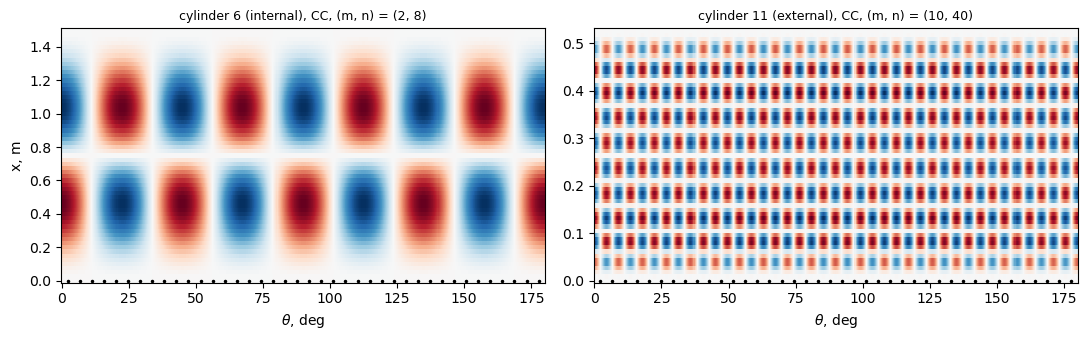

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, c in zip(axes, (6, 11)):
    N, modes, md_, skin = RES[(c, 'A-z', 'CC')][:4]
    plot_mode(ax, md_, modes[0][3], skin, R*IN, 'cylinder %d (%s), CC, (m, n) = (%d, %d)'
              % (c, CYL[c][0], *modes[0][1:3]), NS)
axes[0].set_ylabel('x, m')
plt.tight_layout()
plt.show()

## Z stringers as three plates

The Z is now assembled from three plates of the sheet thickness instead of
an equivalent blade, with
`panels.multidomain.create_cylinder_z_stiffened` (also used by the test of
cylinders 1 and 2 below), called by the helper module
`z_stringer_cylinder.py` of this folder:

- the **attached flange** is bonded continuously to the skin: the strip of
  skin under it is a `cylshell_clpt_sanders` panel of thickness $t + t_z$
  with the offset $\mp t_z/2$, its reference surface remaining the middle
  surface of the skin (the rivets are not represented);
- the **web** is a `plate_clpt_gl` strip connected with `'BFycte'` to the
  edge of the strip, from the middle surface of the skin to the middle
  surface of the free flange (it overlaps skin and flange over $t/2 +
  t_z/2$);
- the **free flange** is a `plate_clpt_gl` strip connected with `'BFycte'`
  at the free edge of the web, on the side opposite to the attached flange.

The Z has no plane of symmetry through the axis, so the whole cylinder is
modelled: 80 stringers give 160 skin panels and 160 plates. The free
flange needs at least 4 terms across: with 3, `MultiDomain` warns
(`ConnectionTermsWarning`) that the connection locks, and the clamped load
of cylinder 6 is 2587 lb/in instead of 1345 lb/in (exploratory run).
Both ends hold the in-section displacements of every plate; the clamped
ends also its axial displacement and slope.

Only the dimensions of Peterson and Dow [1] (Fig. 2(b), p. 12) are used:
sheet 0.040 in, attached flange 0.38 in and free flange 0.22 in overall
from the outer face of the web, depth 0.54 in from the skin to the outer
face of the free flange, inner bend radius 0.04 in (dimensioned at the bend
of the free flange; the other bend is drawn rounded without a dimension).
The plates are the middle lines of the sheet with square corners; the
variant *bends* shortens each flange by $(2 - \pi/2) r_c$, $r_c = 0.04 +
t_z/2$ in, the length saved by a bend of 90 degrees (both bends, a
sensitivity study). The Z of the cells above follows Card and Jones [2]
(attached flange 0.375 in, centre line with the bends). The reference of
the gap is equation (15) of [3] for the section as modelled
(`zs.section_properties`: area, centroid and $I_o$ of the three plates with
the overlap of the web, $J = \sum b t_z^3/3$).

In [6]:
import warnings
import z_stringer_cylinder as zs

TZ_P, BF_P, DEPTH_P, BT_P, RB_P = 0.040, 0.38, 0.54, 0.22, 0.04
ZSEC = {}
rows = []
for c, (side, t, L, Ne, Nc, Ns) in CYL.items():
    for variant, rb in (('square', 0.), ('bends', RB_P)):
        sec = zs.z_midlines(TZ_P, BF_P, DEPTH_P, BT_P, h=t, bend_radius=rb)
        p = zs.section_properties(sec, t, E_PSI, MU)
        sign = 1. if side == 'external' else -1.
        sm = su.smeared_ss(R, L, t, E_PSI, MU, d, p['A'], sign*p['zc'], p['Io'], p['J'], nmax=40)
        ZSEC[(c, variant)] = dict(sec=sec, prop=p, smSS=sm)
        if c in (5, 6):
            print('%s, t = %.4f in: b_f = %.4f, H_w = %.4f, b_l = %.4f in; A = %.5f in^2, centroid %.4f in '
                  'from the middle surface of the skin, I_o = %.4e in^4, J = %.3e in^4'
                  % (variant, t, sec['bf'], sec['Hw'], sec['bl'], p['A'], p['zc'], p['Io'], p['J']))
        rows.append([c, side, variant, '%.0f %s, %+.1f %%' % (sm[0], sm[1], pct(sm[0], Ns))])
table(['cyl.', 'stringers', 'Z model', 'Eq. (15) of the section as modelled, vs N_s'], rows)

square, t = 0.0410 in: b_f = 0.3600, H_w = 0.5405, b_l = 0.2000 in; A = 0.04402 in^2, centroid 0.2442 in from the middle surface of the skin, I_o = 4.4691e-03 in^4, J = 2.348e-05 in^4
bends, t = 0.0410 in: b_f = 0.3342, H_w = 0.5405, b_l = 0.1742 in; A = 0.04196 in^2, centroid 0.2419 in from the middle surface of the skin, I_o = 4.1662e-03 in^4, J = 2.238e-05 in^4
square, t = 0.0401 in: b_f = 0.3600, H_w = 0.5401, b_l = 0.2000 in; A = 0.04400 in^2, centroid 0.2439 in from the middle surface of the skin, I_o = 4.4594e-03 in^4, J = 2.347e-05 in^4
bends, t = 0.0401 in: b_f = 0.3342, H_w = 0.5401, b_l = 0.1742 in; A = 0.04194 in^2, centroid 0.2416 in from the middle surface of the skin, I_o = 4.1571e-03 in^4, J = 2.237e-05 in^4


| cyl. | stringers | Z model | Eq. (15) of the section as modelled, vs N_s |
|---|---|---|---|
| 5 | external | square | 1227 (1, 6), +2.9 % |
| 5 | external | bends | 1201 (1, 6), +0.7 % |
| 6 | internal | square | 776 (1, 6), +1.3 % |
| 6 | internal | bends | 772 (1, 6), +0.8 % |
| 7 | external | square | 1327 (1, 7), +3.4 % |
| 7 | external | bends | 1289 (1, 7), +0.5 % |
| 8 | internal | square | 787 (1, 7), +1.8 % |
| 8 | internal | bends | 780 (1, 7), +0.9 % |
| 9 | external | square | 1630 (1, 9), +3.5 % |
| 9 | external | bends | 1579 (1, 9), +0.3 % |
| 10 | internal | square | 859 (1, 8), +2.5 % |
| 10 | internal | bends | 845 (1, 8), +0.8 % |
| 11 | external | square | 2160 (1, 10), +4.4 % |
| 11 | external | bends | 2074 (1, 10), +0.3 % |
| 12 | internal | square | 1067 (1, 9), +3.9 % |
| 12 | internal | bends | 1036 (1, 9), +0.9 % |

### Convergence of the Z model

Terms `(m_x, n_y, n_f, n_w, n_l)`: along $x$, across a bay, across the strip
under the attached flange, across the web and across the free flange;
cylinders 6 and 11.

In [7]:
ZLEVELS = [(12, 6, 4, 4, 4), (16, 8, 5, 5, 4), (20, 10, 6, 6, 5)]


def zrun(c, bc, lev, variant='square', R_=R, E_=E, ns=NS, t=None, L=None, side=None, num_eigvalues=8):
    if t is None:
        side, t, L = CYL[c][:3]
        sec = ZSEC[(c, variant)]['sec']
    else:
        sec = zs.z_midlines(TZ_P, BF_P, DEPTH_P, BT_P, h=t, bend_radius=RB_P if variant == 'bends' else 0.)
    sec = {k: v*IN for k, v in sec.items()}
    N, modes, md_, groups, ndof, dt = zs.buckling_membrane(
        R_*IN, t*IN, L*IN, E_, MU, ns, sec, side=side, bc=bc, mx=lev[0], ny=lev[1], nf=lev[2],
        nw=lev[3], nl=lev[4], num_eigvalues=num_eigvalues)
    return N/(LBF/IN), modes, md_, groups, ndof, dt


t0 = time.time()
rows = []
for c in (6, 11):
    for bc in ('CC', 'SS'):
        prev = None
        for lev in ZLEVELS:
            N, modes, md_, groups, ndof, dt = zrun(c, bc, lev)
            rows.append([c, bc, lev, ndof, '%.1f' % dt, '%.1f' % N, '(%d, %d)' % modes[0][1:3],
                         '' if prev is None else '%+.2f %%' % pct(N, prev)])
            prev = N
table(['cyl.', 'ends', 'terms', 'dofs', 'time, s', 'N, lb/in', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| cyl. | ends | terms | dofs | time, s | N, lb/in | (m, n) | change |
|---|---|---|---|---|---|---|---|
| 6 | CC | (12, 6, 4, 4, 4) | 40480 | 19.1 | 1345.3 | (2, 8) |  |
| 6 | CC | (16, 8, 5, 5, 4) | 68000 | 53.1 | 1343.8 | (2, 8) | -0.11 % |
| 6 | CC | (20, 10, 6, 6, 5) | 108000 | 100.9 | 1343.2 | (2, 8) | -0.05 % |
| 6 | SS | (12, 6, 4, 4, 4) | 38399 | 19.8 | 907.5 | (1, 6) |  |
| 6 | SS | (16, 8, 5, 5, 4) | 65919 | 45.3 | 907.5 | (1, 6) | -0.00 % |
| 6 | SS | (20, 10, 6, 6, 5) | 105919 | 95.1 | 907.5 | (1, 6) | -0.00 % |
| 11 | CC | (12, 6, 4, 4, 4) | 40480 | 22.7 | 5021.0 | (1, 11) |  |
| 11 | CC | (16, 8, 5, 5, 4) | 68000 | 43.4 | 5005.6 | (1, 11) | -0.31 % |
| 11 | CC | (20, 10, 6, 6, 5) | 108000 | 97.6 | 4999.4 | (1, 11) | -0.12 % |
| 11 | SS | (12, 6, 4, 4, 4) | 38399 | 20.1 | 2252.2 | (1, 10) |  |
| 11 | SS | (16, 8, 5, 5, 4) | 65919 | 43.5 | 2252.2 | (1, 10) | -0.00 % |
| 11 | SS | (20, 10, 6, 6, 5) | 105919 | 106.2 | 2252.2 | (1, 10) | -0.00 % |

667 s


### Z model against the tests, the smeared theory and the equivalent blades

Second level of terms. "gap SS" is the discrete Z model against equation
(15) of the section as modelled; the last two columns are the clamped
values of the equivalent blades above relative to the Z model.

In [8]:
t0 = time.time()
RESZ = {}
for c in CYL:
    for bc in ('CC', 'SS'):
        RESZ[(c, bc)] = zrun(c, bc, ZLEVELS[1])
print('%.0f s' % (time.time() - t0))
rows = []
for c, (side, t, L, Ne, Nc, Ns) in CYL.items():
    Ncc, mcc = RESZ[(c, 'CC')][:2]
    Nss, mss = RESZ[(c, 'SS')][:2]
    sm = ZSEC[(c, 'square')]['smSS'][0]
    blades = ['%.0f (%d, %d), %+.1f %%' % (RES[(c, b, 'CC')][0], *RES[(c, b, 'CC')][1][0][1:3],
                                           pct(RES[(c, b, 'CC')][0], Ncc)) for b in ('A-z', 'A-Io')]
    rows.append([c, side, '%.0f (%d, %d)' % (Ncc, *mcc[0][1:3]), '%+.1f %%' % pct(Ncc, Nc),
                 '%+.1f %%' % pct(Ne, Ncc), '%.0f (%d, %d)' % (Nss, *mss[0][1:3]),
                 '**%+.1f %%**' % pct(Nss, sm), '%+.1f %%' % pct(Nss, Ns)] + blades)
table(['cyl.', 'stringers', 'Z, CC (m, n)', 'vs N_c', 'test N_e vs Z', 'Z, SS (m, n)', 'gap SS',
       'vs N_s', 'blade A-z CC vs Z', 'blade A-Io CC vs Z'], rows)

785 s


| cyl. | stringers | Z, CC (m, n) | vs N_c | test N_e vs Z | Z, SS (m, n) | gap SS | vs N_s | blade A-z CC vs Z | blade A-Io CC vs Z |
|---|---|---|---|---|---|---|---|---|---|
| 5 | external | 2523 (1, 7) | +10.2 % | -32.8 % | 1355 (1, 6) | **+10.4 %** | +13.6 % | 2164 (1, 7), -14.2 % | 2305 (1, 7), -8.6 % |
| 6 | internal | 1344 (2, 8) | +14.5 % | -26.0 % | 907 (1, 6) | **+16.9 %** | +18.5 % | 966 (2, 8), -28.1 % | 1029 (2, 8), -23.4 % |
| 7 | external | 2887 (1, 9) | +10.3 % | -35.5 % | 1438 (1, 7) | **+8.3 %** | +12.0 % | 2392 (1, 9), -17.1 % | 2615 (1, 9), -9.4 % |
| 8 | internal | 1606 (1, 8) | +16.1 % | -21.5 % | 912 (1, 6) | **+15.9 %** | +18.0 % | 1162 (1, 8), -27.6 % | 1225 (1, 8), -23.7 % |
| 9 | external | 3647 (1, 10) | +6.4 % | -25.1 % | 1737 (1, 8) | **+6.6 %** | +10.3 % | 3012 (1, 10), -17.4 % | 3233 (12, 40), -11.3 % |
| 10 | internal | 2039 (1, 9) | +12.5 % | -16.1 % | 986 (1, 7) | **+14.8 %** | +17.7 % | 1424 (1, 9), -30.2 % | 1584 (1, 9), -22.3 % |
| 11 | external | 5006 (1, 11) | +1.2 % | -24.5 % | 2252 (1, 10) | **+4.3 %** | +8.9 % | 3482 (10, 40), -30.4 % | 3066 (10, 40), -38.8 % |
| 12 | internal | 3007 (1, 10) | +5.7 % | -9.2 % | 1192 (1, 9) | **+11.7 %** | +16.0 % | 2066 (1, 10), -31.3 % | 2431 (1, 10), -19.1 % |

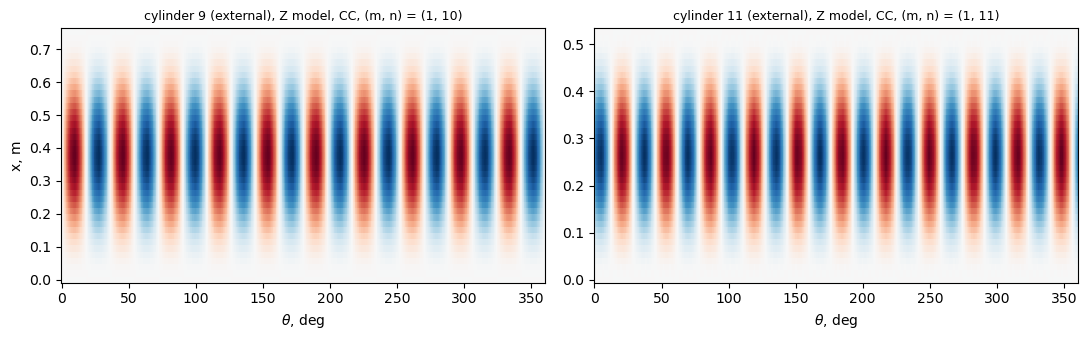

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, c in zip(axes, (9, 11)):
    N, modes, md_, groups = RESZ[(c, 'CC')][:4]
    x, th, w = zs.skin_w(md_, modes[0][3], groups['skin'], R*IN)
    ax.pcolormesh(np.degrees(th), x, (w/np.abs(w).max()).T, cmap='RdBu_r', shading='auto',
                  vmin=-1, vmax=1)
    ax.set_xlabel(r'$\theta$, deg')
    ax.set_title('cylinder %d (%s), Z model, CC, (m, n) = (%d, %d)' % (c, CYL[c][0], *modes[0][1:3]),
                 fontsize=9)
axes[0].set_ylabel('x, m')
plt.tight_layout()
plt.show()

### Sensitivity to the bends

The variant *bends*, clamped and simply supported, against the square
corners:

In [10]:
t0 = time.time()
rows = []
for c in CYL:
    row = [c, CYL[c][0]]
    for bc in ('CC', 'SS'):
        N, modes = zrun(c, bc, ZLEVELS[1], variant='bends')[:2]
        row.append('%.0f (%d, %d), %+.1f %%' % (N, *modes[0][1:3], pct(N, RESZ[(c, bc)][0])))
    rows.append(row)
table(['cyl.', 'stringers', 'bends, CC vs square', 'bends, SS vs square'], rows)
print('%.0f s' % (time.time() - t0))

| cyl. | stringers | bends, CC vs square | bends, SS vs square |
|---|---|---|---|
| 5 | external | 2439 (1, 7), -3.4 % | 1314 (1, 6), -3.0 % |
| 6 | internal | 1303 (2, 8), -3.1 % | 888 (1, 6), -2.1 % |
| 7 | external | 2778 (1, 9), -3.8 % | 1389 (1, 7), -3.4 % |
| 8 | internal | 1559 (1, 8), -2.9 % | 894 (1, 6), -1.9 % |
| 9 | external | 3498 (1, 10), -4.1 % | 1672 (1, 8), -3.8 % |
| 10 | internal | 1964 (1, 9), -3.7 % | 963 (1, 7), -2.4 % |
| 11 | external | 4795 (1, 11), -4.2 % | 2159 (1, 10), -4.1 % |
| 12 | internal | 2876 (1, 10), -4.4 % | 1150 (1, 9), -3.5 % |

775 s


### The attached flange and the smeared theory

The discrete Z model lies above equation (15) of its own section, whereas
the blade models lie below that of theirs. The smeared theory counts the
stringer as a beam and the skin as unstiffened in the circumferential
direction; in the model the attached flange doubles the thickness of the
skin over 29 % of the pitch. The model without the attached flange (the web
and the free flange, an L standing on the skin, `attached_flange=False`),
simply supported, against equation (15) of that section:

In [11]:
t0 = time.time()
rows = []
for c in (5, 6, 11, 12):
    side, t, L = CYL[c][:3]
    sign = 1. if side == 'external' else -1.
    sec = dict(ZSEC[(c, 'square')]['sec'])
    for name, af in (('Z', True), ('without attached flange', False)):
        if af:
            N = RESZ[(c, 'SS')][0]
            p = ZSEC[(c, 'square')]['prop']
        else:
            N, modes = zs.buckling_membrane(R*IN, t*IN, L*IN, E, MU, NS, {k: v*IN for k, v in sec.items()},
                side=side, bc='SS', mx=16, ny=8, nf=5, nw=5, nl=4, attached_flange=False)[:2]
            N /= LBF/IN
            p = zs.section_properties(dict(sec, bf=0.), t, E_PSI, MU)
        sm = su.smeared_ss(R, L, t, E_PSI, MU, d, p['A'], sign*p['zc'], p['Io'], p['J'], nmax=40)
        rows.append([c, side, name, '%.0f' % N, '%.0f %s' % sm, '%+.1f %%' % pct(N, sm[0])])
table(['cyl.', 'stringers', 'model', 'discrete SS, lb/in', 'Eq. (15) of the section as modelled', 'gap'],
      rows)
print('%.0f s' % (time.time() - t0))

| cyl. | stringers | model | discrete SS, lb/in | Eq. (15) of the section as modelled | gap |
|---|---|---|---|---|---|
| 5 | external | Z | 1355 | 1227 (1, 6) | +10.4 % |
| 5 | external | without attached flange | 1126 | 1158 (1, 6) | -2.7 % |
| 6 | internal | Z | 907 | 776 (1, 6) | +16.9 % |
| 6 | internal | without attached flange | 675 | 724 (1, 6) | -6.7 % |
| 11 | external | Z | 2252 | 2160 (1, 10) | +4.3 % |
| 11 | external | without attached flange | 2040 | 2096 (1, 10) | -2.7 % |
| 12 | internal | Z | 1192 | 1067 (1, 9) | +11.7 % |
| 12 | internal | without attached flange | 958 | 1004 (1, 8) | -4.6 % |

203 s


## Cylinders 1 and 2 of Peterson and Dow

Specimens 1 and 2 of [1] (Table I, p. 11): $t_s = 0.0395$ in, $l = 25.40$
and 19.28 in, $R = 23.74$ in, buckling loads (strain reversal) $P_{cr} =
270$ and 413 kips, buckle patterns of 9 (then 10) and 11 circumferential
waves (p. 9); $E = 10\,900$ ksi, $\mu = 0.32$ (p. 4); internal Z stringers
1.25 in apart (Fig. 2(a)), $2\pi R/1.25 = 119.3$. Card and Jones [2] did not
compute these cylinders, so they are compared with the tests only. The
number of stringers is not printed: 120 (1.243 in apart) and 118. Ends
ground flat (clamped). The test of this repository
(`tests/multidomain/test_cylinder_z_stiffened_peterson1959.py`) checks the
model of 120 stringers against these tests with fewer terms.

In [12]:
PET12 = {1: (.0395, 25.40, 270., '9 -> 10'), 2: (.0395, 19.28, 413., '11')}
R12, E12 = 23.74, 10.9e6*bu.PSI
t0 = time.time()
rows = []
for sp, (ts, l, Pcr, waves) in PET12.items():
    Ne1 = Pcr*1e3/(2*np.pi*R12)
    for ns in (120, 118):
        for lev in ZLEVELS[:2]:
            N, modes, md_, groups, ndof, dt = zrun(None, 'CC', lev, R_=R12, E_=E12, ns=ns, t=ts, L=l,
                                                  side='internal')
            rows.append([sp, ns, lev, '%.0f (%d, %d)' % (N, *modes[0][1:3]), '%.1f' % (N*2*np.pi*R12/1e3),
                         '%.0f' % Ne1, '%+.1f %%' % pct(Ne1, N), waves])
table(['specimen', 'stringers', 'terms', 'Z, CC (m, n), lb/in', 'P, kips', 'test N_e, lb/in',
       'test vs Z', 'test waves'], rows)
print('%.0f s' % (time.time() - t0))

| specimen | stringers | terms | Z, CC (m, n), lb/in | P, kips | test N_e, lb/in | test vs Z | test waves |
|---|---|---|---|---|---|---|---|
| 1 | 120 | (12, 6, 4, 4, 4) | 2128 (1, 12) | 317.4 | 1810 | -14.9 % | 9 -> 10 |
| 1 | 120 | (16, 8, 5, 5, 4) | 2121 (1, 12) | 316.4 | 1810 | -14.7 % | 9 -> 10 |
| 1 | 118 | (12, 6, 4, 4, 4) | 2105 (1, 12) | 314.0 | 1810 | -14.0 % | 9 -> 10 |
| 1 | 118 | (16, 8, 5, 5, 4) | 2099 (1, 12) | 313.1 | 1810 | -13.8 % | 9 -> 10 |
| 2 | 120 | (12, 6, 4, 4, 4) | 3194 (1, 13) | 476.4 | 2769 | -13.3 % | 11 |
| 2 | 120 | (16, 8, 5, 5, 4) | 3182 (1, 13) | 474.7 | 2769 | -13.0 % | 11 |
| 2 | 118 | (12, 6, 4, 4, 4) | 3156 (1, 13) | 470.8 | 2769 | -12.3 % | 11 |
| 2 | 118 | (16, 8, 5, 5, 4) | 3145 (1, 13) | 469.1 | 2769 | -12.0 % | 11 |

464 s


## Discussion

- **The Z section.** Read on the centre line of the sheet with its two bends,
  the nominal Z reproduces $\bar{N}_s$ of Card and Jones within 0.2 % with
  equation (15) (the clamped Galerkin solution and the reading with square
  corners, 0.4 to 5.0 % higher, are in the bfsccylinder implementation).
- **Equivalent blades.** Replacing the Z by a blade changes the smeared
  simply supported load by -15.8 to +3.0 %: more than the discreteness
  effect, which is why the gap is measured against the same strip.
- **Discreteness gap**, simply supported, general modes: -1.6 to -2.8 %
  (external) and -4.0 to -6.7 % (internal), the same within 0.4 % for both
  blades; larger for internal stringers. At 1.0 in spacing (card1966
  notebook), cylinder 4 (internal) gives -6.6 % against the strip as modelled.
- **Clamped, tests.** Card and Jones' tests are at 71 to 80 % (external) and
  85 to 96 % (internal) of $\bar{N}_c$. The blade A-Io reproduces $\bar{N}_c$
  within 0.8 % for the external cylinders 5 and 7; for the internal cylinders
  both blades are 11 to 27 % below $\bar{N}_c$.
- **Local buckling.** The blade model leaves the whole 1.25-in pitch of skin
  free; the riveted attached flange of the Z covers 0.375 in of it. For the
  shortest external cylinders the lowest clamped mode of the blade model is
  local, one half-wave of skin per bay ($n = 40$): cylinder 11, 3482 lb/in
  (blade A-z) and 3066 (A-Io), below the test (3780 lb/in, general mode
  $n_e = 8$), and cylinder 9 with the blade A-Io, 3233 lb/in. These modes
  need more axial terms than the general ones (the convergence table for
  cylinder 11 changes by 8 % per step once the local mode appears) and are
  an artifact of the missing flange: with the Z of three plates the lowest
  clamped modes of cylinders 9 and 11 are general, $(1, 10)$ at 3647 lb/in
  and $(1, 11)$ at 5006 lb/in.
- **Z as three plates.** With the attached flange, web and free flange of
  Peterson and Dow's dimensions, the clamped loads are 1.2 to 10.3 %
  (external) and 5.7 to 16.1 % (internal) above $\bar{N}_c$, and the tests
  are 9 to 36 % below them (internal 9 to 26 %, external 24 to 36 %). The
  equivalent blades are 9 to 31 % below the Z model on the general modes
  (blade A-z 14 to 31 %, A-Io 9 to 24 %), and up to 39 % with the local
  modes: the blade sensitivity of the cells above is the error of the
  blade, not of the Z. The convergence with the terms is below 0.4 %.
- **Z against the smeared theory.** Unlike the blades, the discrete Z is
  above equation (15) of its own section, by 4.3 to 10.4 % (external) and
  11.7 to 16.9 % (internal), simply supported. Without the attached flange
  (web and free flange only) the gap is -2.7 to -6.7 %, as for the blades:
  the excess comes from the flange doubling the skin thickness under it,
  29 % of the pitch, a circumferential stiffening of the skin that the
  smeared theory, which treats the stringer as a beam, does not contain.
- **Sensitivity.** The section as modelled has 0.0440 in$^2$, 9.6 % more
  than the centre line with the bends of the cells above, through the
  square corners and the overlap of the web with skin and flange;
  shortening the flanges by the two bends lowers the loads by 1.9 to
  4.4 %. For cylinders 1 and 2, 118 stringers instead of 120 lower them by
  1.0 to 1.2 %.
- **Cylinders 1 and 2** (no value of Card and Jones): the clamped Z model
  gives 2121 and 3182 lb/in with 12 and 13 waves; the tests, 1810 and 2769
  lb/in with 9-10 and 11 waves, are 14.7 and 13.0 % below, the
  "approximately 15 percent" of Peterson and Dow (p. 10).
- **The bfsccylinder implementation of this case**
  (`bfsccylinder/notebooks/peterson1959_stiffened_cylinder_buckling.ipynb`:
  one stringer pitch with cyclic symmetry, the same Z, blades and twisting
  stiffness, harmonics $n \le 20$ plus a check of $n = 40$) agrees within
  0.6 % on the general modes, e.g. cylinder 6, blade A-z, clamped 968 and
  simply supported 703 lb/in (here 966 and 702); its gaps are -1.4 to -2.7 %
  (external) and -3.8 to -6.6 % (internal) simply supported, -1.6 to -3.5 %
  and -3.8 to -5.5 % clamped (against its Galerkin solution for the same
  strip). Its local check of cylinder 11 gives 3424 lb/in at $n = 40$ with
  4 nodes per inch.
  Its Z of three plates (the same plates, the attached flange in a two-layer
  laminate of the skin, one pitch with cyclic symmetry) gives, e.g.,
  cylinder 6 clamped 1347 and simply supported 910 lb/in (here 1344 and
  907), cylinder 11 5021 and 2258 (here 5006 and 2252), and for cylinders
  1 and 2 with the mesh of its test 2128.4 and 3196.1 lb/in (here, with
  the terms of the test, 2127.6 and 3194.0).
- **Not modelled**: rivets (the attached flange is bonded continuously),
  lap joints, the bends of the Z (sensitivity above), plasticity.